# Document Understanding with LayoutLMv3
### Key-value extraction from scanned forms (FUNSD, Hugging Face, Tesseract OCR)

Fine-tuning LayoutLMv3 to label every word on a scanned form as a **question** (field name), **answer** (filled-in
value), **header** or **other**, then linking questions to answers to produce structured key-value output.

**Pipeline**

```
Scanned image
  → OCR (Tesseract): words + pixel bounding boxes
  → box normalisation to the 0–1000 grid
  → LayoutLMv3 (text + layout + image)
  → token classification (BIO: QUESTION / ANSWER / HEADER / O)
  → key-value linking  {"NAME:": "John Smith", "DATE:": "12.05.2026"}
```

Trained on a single GPU; fine-tuning takes about 5 minutes (1,000 steps).

## 0. Background: LayoutLMv3

A text-only model like BERT ignores *where* a word sits on the page, but on a form, position carries meaning: "Smith"
to the right of "Name:" is an answer to that field. LayoutLMv3 combines three signals per token in a single
Transformer:

| Signal | Input |
|---|---|
| Text | token embedding of the word |
| Layout | the word's bounding box (x0, y0, x1, y1) on a 0–1000 grid |
| Image | the page split into 16 × 16 patches (ViT-style patch embedding) |

## 1. Install the libraries

What each one is for:
- **transformers** → the LayoutLMv3 model and its processor
- **datasets** → loads the FUNSD dataset in one line
- **seqeval** → the standard metric library for sequence-labeling (gives precision/recall/F1 per entity type)
- **pytesseract + tesseract-ocr** → the OCR engine that turns pixels into words + boxes
- **evaluate** → Hugging Face's wrapper around metrics


In [1]:
# Install Python libraries (quiet mode to keep the output clean)
!pip install -q transformers datasets seqeval evaluate pytesseract pillow

# Install the Tesseract OCR engine itself (a system program, not a Python package)
!apt-get install -y -qq tesseract-ocr

import transformers, torch
print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

  DEPRECATION: Building 'seqeval' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'seqeval'. Discussion can be found at https://github.com/pypa/pip/issues/6334
E: Could not open lock file /var/lib/dpkg/lock-frontend - open (13: Permission denied)
E: Unable to acquire the dpkg frontend lock (/var/lib/dpkg/lock-frontend), are you root?
Transformers version: 5.7.0
GPU available: True


## 2. Dataset: FUNSD

**FUNSD** (*Form Understanding in Noisy Scanned Documents*, Jaume et al., 2019): 199 noisy scanned forms, split into
149 for training and 50 for testing. Every word is annotated with a bounding box and a label (`HEADER`, `QUESTION`,
`ANSWER`, `OTHER`). I use the pre-formatted `nielsr/funsd-layoutlmv3` version.

> **Training vs. inference input:** training uses FUNSD's gold-standard words and boxes. For a new, unannotated
> document (Section 9), Tesseract OCR produces the words and boxes instead.

In [2]:
from datasets import load_dataset

# Load the FUNSD dataset, pre-formatted for LayoutLMv3
dataset = load_dataset("nielsr/funsd-layoutlmv3")

print(dataset)
print()

example = dataset["train"][0]
print("Keys of one example:", list(example.keys()))
print()
print("First 10 words :", example["tokens"][:10])
print("First 10 boxes :", example["bboxes"][:10])
print("First 10 tags  :", example["ner_tags"][:10])

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'bboxes', 'ner_tags', 'image'],
        num_rows: 149
    })
    test: Dataset({
        features: ['id', 'tokens', 'bboxes', 'ner_tags', 'image'],
        num_rows: 50
    })
})

Keys of one example: ['id', 'tokens', 'bboxes', 'ner_tags', 'image']

First 10 words : ['R&D', ':', 'Suggestion:', 'Date:', 'Licensee', 'Yes', 'No', '597005708', 'R&D', 'QUALITY']
First 10 boxes : [[383, 91, 493, 175], [287, 316, 295, 327], [124, 355, 221, 370], [632, 268, 679, 282], [670, 309, 748, 323], [604, 605, 633, 619], [715, 603, 738, 617], [688, 904, 841, 926], [335, 201, 555, 229], [335, 201, 555, 229]]
First 10 tags  : [0, 3, 3, 3, 5, 3, 3, 0, 1, 2]


### 2.1 Understanding the labels (BIO scheme)

The dataset uses the **BIO** tagging scheme — the standard format for "span labeling" tasks:

- **B-** = *Beginning* of an entity (the first word)
- **I-** = *Inside* an entity (continuation words)
- **O** = *Outside* — the word belongs to no entity

Example — the field label `"Date of Birth:"` is one QUESTION made of 3 words:

| Word | Tag |
|---|---|
| Date | **B-QUESTION** |
| of | **I-QUESTION** |
| Birth: | **I-QUESTION** |
| 12.05.1998 | **B-ANSWER** |

Why BIO and not just "QUESTION/ANSWER"? Because two *separate* questions can sit next to each other. The **B-** tag tells us where a new entity starts, so we can split them correctly.


In [3]:
# Get the label names and build id <-> label mappings
features = dataset["train"].features
label_list = features["ner_tags"].feature.names

id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}

print("All labels:", label_list)
print("Number of labels:", len(label_list))

All labels: ['O', 'B-HEADER', 'I-HEADER', 'B-QUESTION', 'I-QUESTION', 'B-ANSWER', 'I-ANSWER']
Number of labels: 7


### 2.2 Visualize a training example

Draw the bounding boxes on the page, colored by label:

- blue = QUESTION (field name)
- green = ANSWER (filled-in value)
- orange = HEADER (section title)
- grey = OTHER

One detail: FUNSD boxes are **normalized to a 0–1000 grid** (so they're independent of image resolution). To draw them on the real image, we scale them back to pixel coordinates.


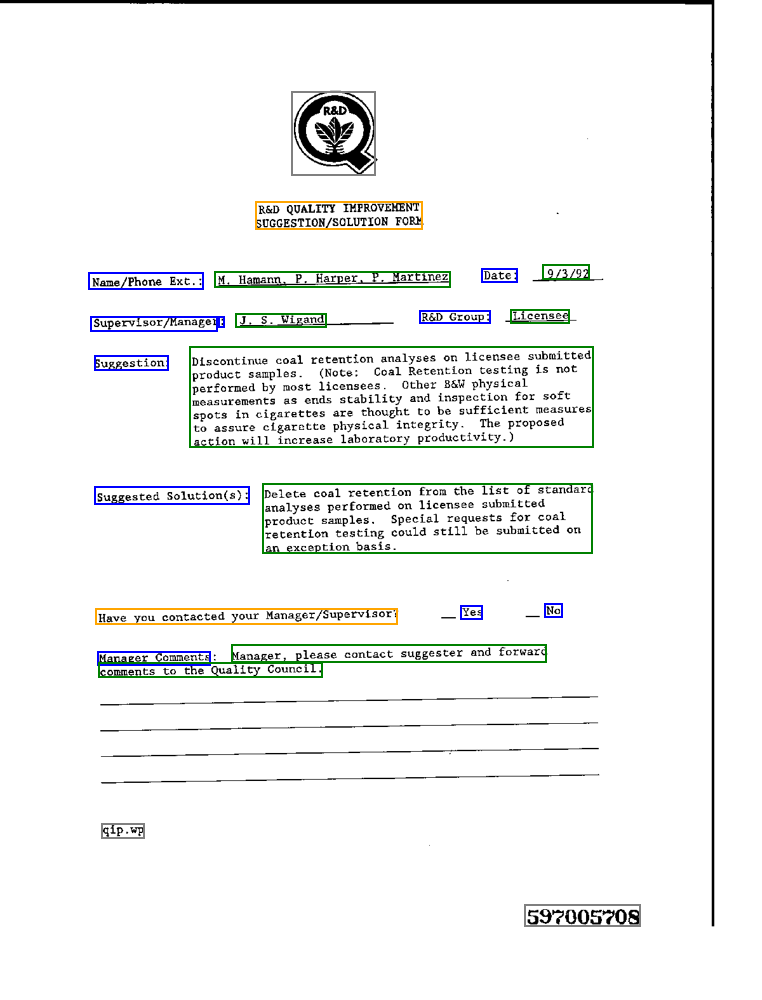

In [4]:
from PIL import ImageDraw, ImageFont

label_colors = {
    "QUESTION": "blue",
    "ANSWER": "green",
    "HEADER": "orange",
    "O": "gray",
}

def simplify(label):
    """Turn 'B-QUESTION' / 'I-QUESTION' into just 'QUESTION'."""
    return label.split("-")[-1] if label != "O" else "O"

def unnormalize_box(box, width, height):
    """Convert a 0-1000 normalized box back to pixel coordinates."""
    return [
        width  * box[0] / 1000,
        height * box[1] / 1000,
        width  * box[2] / 1000,
        height * box[3] / 1000,
    ]

example = dataset["train"][0]
image = example["image"].convert("RGB")
w, h = image.size

draw = ImageDraw.Draw(image)
for box, tag_id in zip(example["bboxes"], example["ner_tags"]):
    label = simplify(id2label[tag_id])
    color = label_colors.get(label, "gray")
    draw.rectangle(unnormalize_box(box, w, h), outline=color, width=2)

image  # display

## 3. Preprocessing with the LayoutLMv3 processor

The processor combines an image processor (resize the page to 224 × 224 and normalise) and a tokenizer (BPE sub-words
with a bounding box attached to every token).

**Token–box alignment.** Annotations and OCR give one box per *word*, but the tokenizer can split a word into several
sub-word tokens:

```
word:   "Birthdate"          box: [120, 80, 210, 100]
tokens: "Birth" + "date"     →  both tokens get the same box
```

Only the first sub-token keeps the word's label; the rest get `-100`, which the loss ignores, so long words are not
counted several times. `apply_ocr=False` because FUNSD already provides words and boxes.

In [5]:
from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained(
    "microsoft/layoutlmv3-base",
    apply_ocr=False,   # we already have words + boxes from the dataset
)

def preprocess(examples):
    images = [img.convert("RGB") for img in examples["image"]]
    encoding = processor(
        images,
        examples["tokens"],            # the words
        boxes=examples["bboxes"],      # one box per word
        word_labels=examples["ner_tags"],  # one label per word
        truncation=True,
        padding="max_length",          # pad every page to 512 tokens
    )
    return encoding

# Apply to the whole dataset (this runs once and is cached)
column_names = dataset["train"].column_names
train_ds = dataset["train"].map(preprocess, batched=True, remove_columns=column_names)
test_ds  = dataset["test"].map(preprocess,  batched=True, remove_columns=column_names)

train_ds.set_format("torch")
test_ds.set_format("torch")

print("Model inputs:", train_ds.column_names)
print("input_ids shape :", train_ds[0]["input_ids"].shape)
print("bbox shape      :", train_ds[0]["bbox"].shape)       # one box per token
print("pixel_values    :", train_ds[0]["pixel_values"].shape) # the page image

Model inputs: ['input_ids', 'attention_mask', 'bbox', 'labels', 'pixel_values']
input_ids shape : torch.Size([512])
bbox shape      : torch.Size([512, 4])
pixel_values    : torch.Size([3, 224, 224])


**Check what the model actually receives** — four tensors per page:

| Tensor | Shape | Meaning |
|---|---|---|
| `input_ids` | (512,) | the token IDs (the text) |
| `bbox` | (512, 4) | one bounding box per token (the layout) |
| `pixel_values` | (3, 224, 224) | the page image (the visual signal) |
| `labels` | (512,) | the target label per token (-100 = ignore) |

This is the multimodal part: **text + layout + image, all together.**


## 4. Load the model

`LayoutLMv3ForTokenClassification` is the pretrained LayoutLMv3-base backbone (pretrained on 11 M document images)
plus a new linear head for the 7 BIO labels. The warning that the classifier weights are newly initialised is
expected.

In [6]:
from transformers import LayoutLMv3ForTokenClassification

model = LayoutLMv3ForTokenClassification.from_pretrained(
    "microsoft/layoutlmv3-base",
    id2label=id2label,
    label2id=label2id,
)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Total parameters: {n_params:.1f} M")

[transformers] LayoutLMv3ForTokenClassification LOAD REPORT from: microsoft/layoutlmv3-base
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 125.3 M


## 5. Evaluation metric: entity-level F1 with `seqeval`

**Why not plain accuracy?** Because ~most tokens are `O` (other). A dumb model that predicts `O` everywhere would already get high accuracy but find zero fields. Useless.

**seqeval** instead measures at the **entity level**: a QUESTION entity counts as correct only if **all its words** are labeled correctly. This is strict — and that's good.

- **Precision** = of the entities the model predicted, how many were right? *(few false alarms)*
- **Recall** = of the true entities, how many did the model find? *(few misses)*
- **F1** = the balance of both

One technical step: we must **filter out the -100 positions** (padding + sub-word continuations) before computing the metric, otherwise the numbers would be polluted.


In [7]:
import numpy as np
import evaluate

metric = evaluate.load("seqeval")

def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=2)  # pick the most likely label per token

    # Keep only real tokens (drop the -100 ignore positions)
    true_predictions = [
        [id2label[pred] for (pred, lab) in zip(prediction, label) if lab != -100]
        for prediction, label in zip(predictions, labels)
    ]
    true_labels = [
        [id2label[lab] for (pred, lab) in zip(prediction, label) if lab != -100]
        for prediction, label in zip(predictions, labels)
    ]

    results = metric.compute(predictions=true_predictions, references=true_labels)
    return {
        "precision": results["overall_precision"],
        "recall":    results["overall_recall"],
        "f1":        results["overall_f1"],
        "accuracy":  results["overall_accuracy"],
    }

## 6. Fine-tuning with the Hugging Face `Trainer`

| Setting | Value | Reason |
|---|---|---|
| learning rate | 1e-5 | small, to fine-tune without destroying pretrained knowledge |
| max_steps | 1000 | FUNSD is small (149 pages); about 13 epochs |
| batch size | 2 | 512-token sequences plus an image per sample |
| eval every | 100 steps | track F1 and spot overfitting |

In [10]:
from transformers import TrainingArguments, Trainer
from transformers.data.data_collator import default_data_collator

training_args = TrainingArguments(
    output_dir="layoutlmv3-funsd",
    max_steps=1000,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    learning_rate=1e-5,
    eval_strategy="steps",        # (older transformers versions: evaluation_strategy)
    eval_steps=100,
    save_strategy="no",           # keep the notebook light; save manually at the end
    logging_steps=50,
    load_best_model_at_end=False,
    report_to="none",             # set to "mlflow" or "wandb" to track experiments
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    processing_class=processor,   # ← was: tokenizer=processor
    data_collator=default_data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Step,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
100,0.892715,0.670905,0.717668,0.829701,0.769629,0.774773
200,0.494706,0.540327,0.813543,0.864673,0.838329,0.814624
300,0.401514,0.493363,0.830614,0.877344,0.853340,0.836764
400,0.269516,0.482783,0.846339,0.890522,0.867869,0.849210
500,0.194079,0.498499,0.870289,0.901166,0.885458,0.851245
600,0.161122,0.535167,0.861275,0.890522,0.875654,0.845022
700,0.123451,0.561995,0.880568,0.911809,0.895916,0.857946
800,0.113475,0.601358,0.870123,0.893056,0.881441,0.841910
900,0.097728,0.595704,0.884596,0.905220,0.894790,0.856151
1000,0.088978,0.590515,0.887506,0.903700,0.895530,0.856032


TrainOutput(global_step=1000, training_loss=0.33248670196533203, metrics={'train_runtime': 283.3239, 'train_samples_per_second': 7.059, 'train_steps_per_second': 3.53, 'total_flos': 523783817001984.0, 'train_loss': 0.33248670196533203, 'epoch': 13.333333333333334})

## 7. Final evaluation

For reference, the LayoutLMv3 paper reports about 90 entity F1 on FUNSD for LayoutLMv3-base and about 92 for
LayoutLMv3-large; text-only BERT-base is around 60. The gap shows how much information the layout and image signals
add.

In [ ]:
results = trainer.evaluate()
for k, v in results.items():
    if isinstance(v, float):
        print(f"{k:25s} {v:.4f}")

## 8. Inference + visualization on a test document

Now we run the fine-tuned model on a test page it has never seen and draw its predictions.

The steps:
1. Encode the page (same processor as training)
2. Forward pass → **logits** = one score per label per token
3. `argmax` → the predicted label per token
4. Keep only the prediction of the **first sub-token of each word** (the others were never trained — they were -100)
5. Draw the boxes, colored by the predicted label


In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

def predict_words(image, words, boxes):
    """Run the model on one page. Returns one predicted label per WORD."""
    encoding = processor(
        image.convert("RGB"), words, boxes=boxes,
        truncation=True, padding="max_length", return_tensors="pt",
    )
    # word_ids maps each token back to its word index (None = special/padding token)
    word_ids = encoding.word_ids(0)
    encoding = {k: v.to(device) for k, v in encoding.items()}

    with torch.no_grad():
        logits = model(**encoding).logits           # shape: (1, 512, num_labels)
    token_preds = logits.argmax(-1).squeeze().tolist()

    # Keep the prediction of the FIRST sub-token of every word
    word_preds = {}
    for idx, w_id in enumerate(word_ids):
        if w_id is not None and w_id not in word_preds:
            word_preds[w_id] = id2label[token_preds[idx]]
    return [word_preds[i] for i in range(len(words))]

# Pick a test page and predict
example = dataset["test"][0]
image = example["image"].convert("RGB")
words, boxes = example["tokens"], example["bboxes"]

pred_labels = predict_words(image, words, boxes)

# Draw predictions
vis = image.copy()
draw = ImageDraw.Draw(vis)
w, h = vis.size
for box, label in zip(boxes, pred_labels):
    color = label_colors.get(simplify(label), "gray")
    draw.rectangle(unnormalize_box(box, w, h), outline=color, width=2)

vis

## 9. Full OCR pipeline on a new document

For a document without annotations:

1. Tesseract OCR returns each word with a pixel bounding box and a confidence score
2. Low-confidence and empty detections are filtered out
3. Pixel boxes are normalised to the 0–1000 grid: `x_norm = x_px / width × 1000`, `y_norm = y_px / height × 1000`
4. Words, boxes and image go through the fine-tuned model

Requires the Tesseract binary (`apt-get install tesseract-ocr`).

In [ ]:
import pytesseract
from pytesseract import Output

def ocr_with_boxes(image, min_confidence=30):
    """Run Tesseract on an image.
    Returns: words (list of str), boxes (list of [x0,y0,x1,y1] normalized 0-1000)."""
    w, h = image.size
    data = pytesseract.image_to_data(image, output_type=Output.DICT)

    words, boxes = [], []
    for i in range(len(data["text"])):
        word = data["text"][i].strip()
        conf = int(data["conf"][i])
        if word == "" or conf < min_confidence:
            continue  # skip empty / low-confidence OCR junk

        # Tesseract gives pixel coords: left, top, width, height
        x, y, bw, bh = data["left"][i], data["top"][i], data["width"][i], data["height"][i]

        # ---- THE ALIGNMENT STEP: pixel box -> 0-1000 normalized box ----
        box = [
            int(1000 * x / w),
            int(1000 * y / h),
            int(1000 * (x + bw) / w),
            int(1000 * (y + bh) / h),
        ]
        # clip to valid range (OCR can slightly overshoot the page)
        box = [min(max(c, 0), 1000) for c in box]
        words.append(word)
        boxes.append(box)
    return words, boxes

# Demo: take a raw test image and pretend it is a brand-new scan
new_scan = dataset["test"][1]["image"].convert("RGB")

ocr_words, ocr_boxes = ocr_with_boxes(new_scan)
print(f"Tesseract found {len(ocr_words)} words")
print("First 10:", ocr_words[:10])

# Run the fine-tuned model on the OCR output
ocr_preds = predict_words(new_scan, ocr_words, ocr_boxes)

# Visualize
vis = new_scan.copy()
draw = ImageDraw.Draw(vis)
w, h = vis.size
for box, label in zip(ocr_boxes, ocr_preds):
    color = label_colors.get(simplify(label), "gray")
    draw.rectangle(unnormalize_box(box, w, h), outline=color, width=2)
vis

> **Note:** accuracy on OCR input is usually lower than on the gold annotations. Tesseract misreads, merges or
> splits words and misses faint text, and the model can only label what OCR gives it. Image quality checks before
> OCR therefore matter a lot in production.

## 10. Key-Value extraction: pairing QUESTIONS with ANSWERS

The final step. The model gave us labeled words; now we want structured output:

```json
{"NAME:": "John Smith", "DATE:": "12.05.2026"}
```

Two sub-steps:

**Step 1 — Group words into entities.** Walk through the words: a `B-` tag starts a new entity, following `I-` tags of the same type extend it.

**Step 2 — Link each QUESTION to its ANSWER with a simple spatial rule.** On forms, the answer is almost always **to the right of** or **directly below** its question. So for each QUESTION we pick the *nearest* ANSWER that lies right-of or below it (nearest by center-to-center distance).

This rule-based linking is simple and transparent. (FUNSD actually ships ground-truth links, and there are learned approaches — e.g. LayoutLMv2/XLM relation-extraction heads — but a distance heuristic is a strong, explainable baseline.)


In [ ]:
def group_entities(words, boxes, labels):
    """Merge BIO-labeled words into whole entities.
    Returns a list of dicts: {text, type, box}."""
    entities = []
    current = None
    for word, box, label in zip(words, boxes, labels):
        if label.startswith("B-"):
            if current: entities.append(current)
            current = {"text": word, "type": label[2:], "box": list(box)}
        elif label.startswith("I-") and current and current["type"] == label[2:]:
            current["text"] += " " + word
            # grow the box to cover the whole entity
            current["box"] = [
                min(current["box"][0], box[0]), min(current["box"][1], box[1]),
                max(current["box"][2], box[2]), max(current["box"][3], box[3]),
            ]
        else:
            if current: entities.append(current)
            current = None
    if current: entities.append(current)
    return entities

def center(box):
    return ((box[0] + box[2]) / 2, (box[1] + box[3]) / 2)

def link_key_value(entities, max_dist=250):
    """Pair each QUESTION with the nearest ANSWER to its right or below."""
    questions = [e for e in entities if e["type"] == "QUESTION"]
    answers   = [e for e in entities if e["type"] == "ANSWER"]
    pairs = {}
    used = set()
    for q in questions:
        qx, qy = center(q["box"])
        best, best_d = None, float("inf")
        for i, a in enumerate(answers):
            if i in used:
                continue
            ax, ay = center(a["box"])
            is_right = ax > qx and abs(ay - qy) < 30   # same line, to the right
            is_below = ay > qy and abs(ax - qx) < 120  # roughly same column, below
            if is_right or is_below:
                d = ((ax - qx) ** 2 + (ay - qy) ** 2) ** 0.5
                if d < best_d and d < max_dist:
                    best, best_d = i, d
        if best is not None:
            used.add(best)
            pairs[q["text"]] = answers[best]["text"]
    return pairs

# Run the full chain on the annotated test page from Section 8
entities = group_entities(words, boxes, pred_labels)
print(f"Found {len(entities)} entities "
      f"({sum(e['type']=='QUESTION' for e in entities)} questions, "
      f"{sum(e['type']=='ANSWER' for e in entities)} answers)\n")

kv = link_key_value(entities)
print("Extracted key-value pairs:")
print("-" * 50)
for k, v in list(kv.items())[:15]:
    print(f"  {k:30s} ->  {v}")

## 11. Save the model

`save_pretrained` stores the fine-tuned weights and processor for reuse without retraining (ONNX export is possible
via `optimum`).

In [ ]:
save_dir = "layoutlmv3-funsd-final"
model.save_pretrained(save_dir)
processor.save_pretrained(save_dir)
print("Saved to:", save_dir)

# To reload later:
# model = LayoutLMv3ForTokenClassification.from_pretrained(save_dir)
# processor = AutoProcessor.from_pretrained(save_dir, apply_ocr=False)

---
## 12. Summary

LayoutLMv3-base fine-tuned on FUNSD reaches **entity-level F1 0.896** (precision 0.888, recall 0.904) on the 50 test
forms after 1,000 steps, in line with the ~0.90 reported in the paper. F1 plateaus from about step 700 while
validation loss starts rising after step 400, so a shorter schedule or early stopping would be enough.

**Limitations and next steps**
- The test split was also used for evaluation during training (FUNSD has no separate validation set); a held-out
  split of the training data would give a cleaner estimate.
- The key-value linking is a distance heuristic; a learned relation-extraction head would handle multi-column layouts.
- Real-world accuracy depends on OCR quality on the input scans.

**References**
- Y. Huang et al. (2022), *LayoutLMv3: Pre-training for Document AI with Unified Text and Image Masking*, arXiv:2204.08387
- G. Jaume, H. K. Ekenel and J.-P. Thiran (2019), *FUNSD: A Dataset for Form Understanding in Noisy Scanned Documents*
- Fine-tuning approach based on N. Rogge, *Transformers-Tutorials* (Hugging Face)